# 04 · Feature engineering (Phase 4)
Features are computed **on the grid** (so neighbours exist), then flattened into one row per ocean cell-day.
Definitions: `configs/features.yaml`; code: `src/oceanembed_ml/features/`. Leakage tests: `tests/test_features.py`.

In [1]:
import json, warnings
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
from oceanembed_ml.config import ROOT, AUDIT, INTERIM, PROCESSED, FINAL, FIGURES, load_yaml
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
print("project root:", ROOT)

project root: D:\Ml project


In [2]:
F = load_yaml("features.yaml")["groups"]
pd.DataFrame([(g, ", ".join(c), len(c)) for g, c in F.items()], columns=["group","features","n"])

,group,features,n
0,direct,"sst, sss, sla, uo, vo, u10, v10",7
1,kinematic,"wind_speed, current_speed",2
2,wind_forcing,"taux, tauy, curl_tau, ekman_w",4
3,gradients,"sst_grad, sla_dx, sla_dy, sla_grad, sla_lap",5
4,neighbourhood,"sla_box5, sst_box5, sss_box5",3
5,temporal,"sla_mean7, sst_mean7, ekman_mean7, sla_change7...",5
6,anomaly,sst_anom,1
7,geographic,"lat, lon",2
8,seasonal,"sin_doy, cos_doy",2
9,static,bottom_depth,1


In [3]:
fs = json.loads((AUDIT/"features_summary.json").read_text())
pd.DataFrame({k: {kk: v[kk] for kk in ["rows","days","columns","months","date_range","size_MB"]} for k, v in fs["tables"].items()}).T

,rows,days,columns,months,date_range,size_MB
train,2245320,189,92,"[1, 3, 4, 6, 7, 9, 10, 12]","[2021-01-01, 2021-12-31]",616.8
test,1425600,120,92,"[2, 5, 8, 11]","[2021-02-01, 2021-11-30]",408.8


## Train-table sample (300k rows) — how each feature relates to the anomaly at 100 m and 1000 m

In [4]:
import pyarrow.parquet as pq
feat = [c for g in F.values() for c in g]
tr = pq.read_table(FINAL/"features"/"train.parquet").to_pandas().sample(300_000, random_state=42)
corr = pd.DataFrame({d: tr[feat].corrwith(tr[f"a_d{k:02d}"], method="spearman") for d, k in [("0 m",0),("100 m",7),("300 m",11),("1000 m",14)]})
corr.round(2).sort_values("100 m", key=abs, ascending=False)

,0 m,100 m,300 m,1000 m
sla_mean7,0.18,0.51,0.32,0.23
sla,0.19,0.50,0.32,0.24
sla_box5,0.19,0.50,0.31,0.24
emb_1,-0.24,-0.44,-0.10,-0.18
sss_box5,-0.11,-0.29,0.05,-0.11
sss,-0.11,-0.29,0.05,-0.11
emb_3,-0.02,0.26,0.25,0.16
lon,0.15,0.26,-0.13,0.26
sla_lap,-0.05,-0.26,-0.19,-0.11
sst_box5,0.25,0.23,0.03,0.08


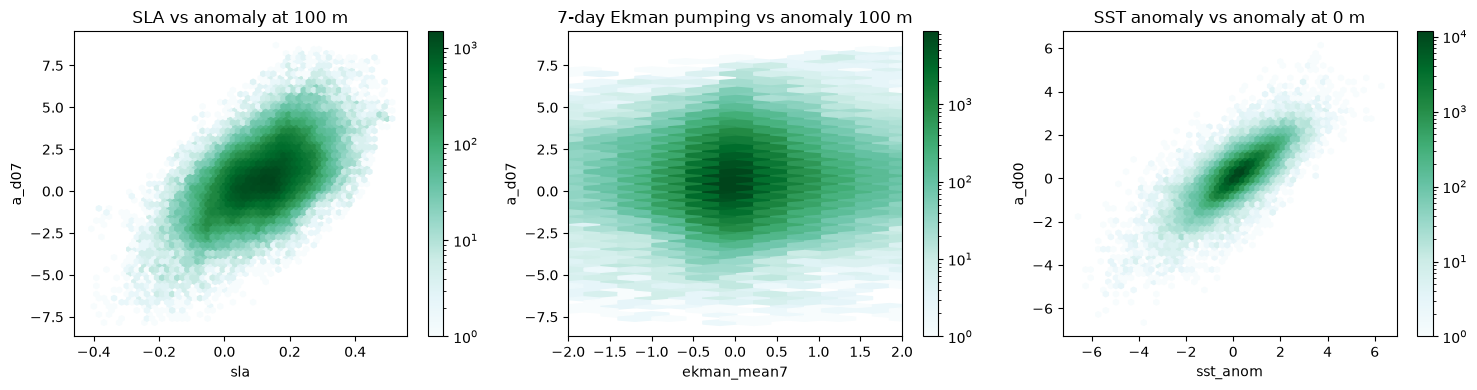

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
tr.plot.hexbin(x="sla", y="a_d07", gridsize=60, bins="log", ax=ax[0], title="SLA vs anomaly at 100 m")
tr.plot.hexbin(x="ekman_mean7", y="a_d07", gridsize=60, bins="log", ax=ax[1], title="7-day Ekman pumping vs anomaly 100 m"); ax[1].set_xlim(-2, 2)
tr.plot.hexbin(x="sst_anom", y="a_d00", gridsize=60, bins="log", ax=ax[2], title="SST anomaly vs anomaly at 0 m")
plt.tight_layout(); plt.show()

## Missing values per feature (handled inside model pipelines in Phase 5, not here)

In [6]:
nan = pd.DataFrame({k: v["feature_nan_frac"] for k, v in fs["tables"].items()})
nan[nan.max(axis=1) > 0].sort_values("train", ascending=False)

,train,test
sla_lap,0.11044,0.11044
sst_grad,0.06111,0.06111
sla_grad,0.05943,0.05943
ekman_mean7,0.05943,0.05943
curl_tau,0.05943,0.05943
ekman_w,0.05943,0.05943
sla_dx,0.04141,0.04141
sla_dy,0.03923,0.03923
sst_change7,0.03866,0.00168
sla_change7,0.03704,0.00000


## PCA surface embedding (fit on train days only)

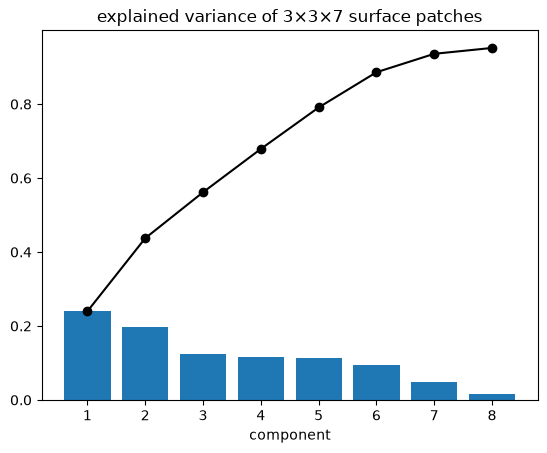

In [7]:
e = np.load(FINAL/"features"/"embedding_pca.npz")
plt.bar(range(1, 9), e["explained_variance_ratio"]); plt.plot(range(1, 9), np.cumsum(e["explained_variance_ratio"]), "ko-")
plt.title("explained variance of 3×3×7 surface patches"); plt.xlabel("component"); plt.show()